# Is Karachi sinking? InSAR time series step by step

The first notebook used the **strength** of the radar echo. This one uses its **phase**: where in its wave cycle the
echo returns. Sentinel-1 passes over the same place every 12 days from almost the same position. If the ground moved
a little towards or away from the satellite between two passes, the echo's path changed length and its phase shifted.
Differencing the phase of two passes gives an **interferogram**; a series of interferograms gives a **time series** of
ground motion with millimetre precision.

Karachi pumps groundwater and builds on young coastal sediment, both of which make ground compact and sink. Here we
measure it.

**Data.** 76 interferograms from 31 Sentinel-1 acquisitions (relative orbit 42, ascending, January 2023 to December
2024), processed on demand by the Alaska Satellite Facility's **HyP3** service (free with a NASA Earthdata login), at
80 m. The full analysis used **MintPy**; this notebook works on a 30 × 28 km crop of east Karachi averaged to 160 m,
and does the core steps itself in numpy so you can see what MintPy does.

In [1]:
import urllib.request
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110})
BASE = "https://raw.githubusercontent.com/AhmadAmmar/AhmadAmmar.github.io/main/guides/radar-python/notebooks/data_local/"
F = "karachi_insar_crop.npz"
DATA, LOCAL = Path("data"), Path("data_local")
DATA.mkdir(exist_ok=True)
if not (DATA / F).exists():
    (DATA / F).write_bytes((LOCAL / F).read_bytes() if (LOCAL / F).exists() else urllib.request.urlopen(BASE + F, timeout=300).read())
z = np.load(DATA / F)
unw, coh = z["unw"].astype("float32"), z["coh"].astype("float32")
pairs = [list(p) for p in z["dates"]]          # each row: first date, second date
lam = float(z["wavelength"])
print("interferograms, rows, columns:", unw.shape, " wavelength (m):", round(lam, 4))
ext = [z["x0"] / 1e3, z["x0"] / 1e3 + unw.shape[2] * z["cell"] / 1e3, z["y1"] / 1e3 - unw.shape[1] * z["cell"] / 1e3, z["y1"] / 1e3]

interferograms, rows, columns: (68, 175, 187)  wavelength (m): 0.0555


# From phase to millimetres

The radar wave travels to the ground and back, so a change $\Delta R$ in the one-way distance changes the phase by

$$ \Delta\phi = -\frac{4\pi}{\lambda}\,\Delta R \qquad\Longleftrightarrow\qquad \Delta R = -\frac{\lambda}{4\pi}\,\Delta\phi $$

With λ = 5.55 cm, one full cycle (2π) is 2.8 cm of motion along the line of sight. The phase is only known modulo
2π (a "wrapped" interferogram shows fringes); HyP3 **unwraps** it with SNAPHU, adding the right multiple of 2π to
make it continuous. **Coherence** (0 to 1) says how similar the two echoes were: water and moving sand decorrelate
(low coherence) and their phase is noise; buildings and bare rock stay coherent.

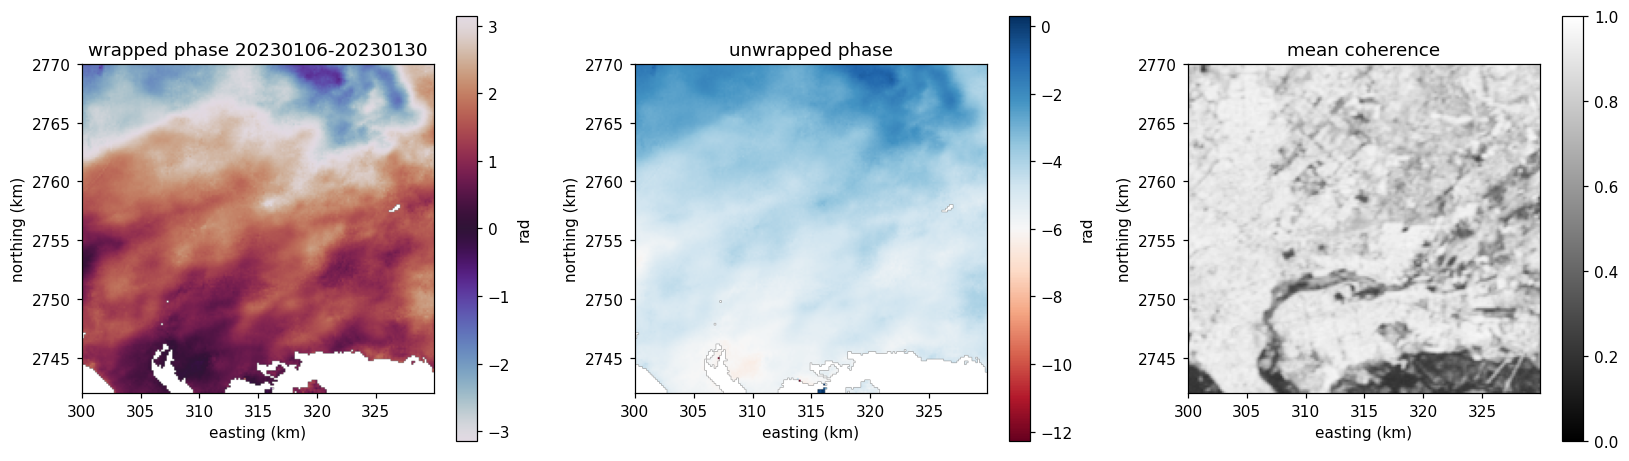

In [2]:
k = 0
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
im = ax[0].imshow(np.angle(np.exp(1j * unw[k])), cmap="twilight", extent=ext); ax[0].set_title(f"wrapped phase {pairs[k][0]}-{pairs[k][1]}")
plt.colorbar(im, ax=ax[0], label="rad")
im = ax[1].imshow(unw[k], cmap="RdBu", extent=ext); ax[1].set_title("unwrapped phase"); plt.colorbar(im, ax=ax[1], label="rad")
im = ax[2].imshow(np.nanmean(coh, 0), cmap="gray", vmin=0, vmax=1, extent=ext); ax[2].set_title("mean coherence")
plt.colorbar(im, ax=ax[2])
for a in ax: a.set_xlabel("easting (km)"); a.set_ylabel("northing (km)")
plt.tight_layout(); plt.show()

The single interferogram is dominated by smooth patterns tens of kilometres wide: mostly the **atmosphere** (water
vapour delays the wave differently on the two dates) and small orbit errors. Ground motion of a few millimetres in 24
days is hidden underneath. A time series separates them: motion accumulates with time, the atmosphere does not.

# The network of pairs

Each interferogram links two dates. Short pairs (24, 48 days) keep coherence high; year-long pairs tie the network
across seasons. Pairs with poor average coherence were dropped by MintPy, leaving the network below.
The **perpendicular baseline** is the distance between the two orbits; it controls sensitivity to DEM errors.

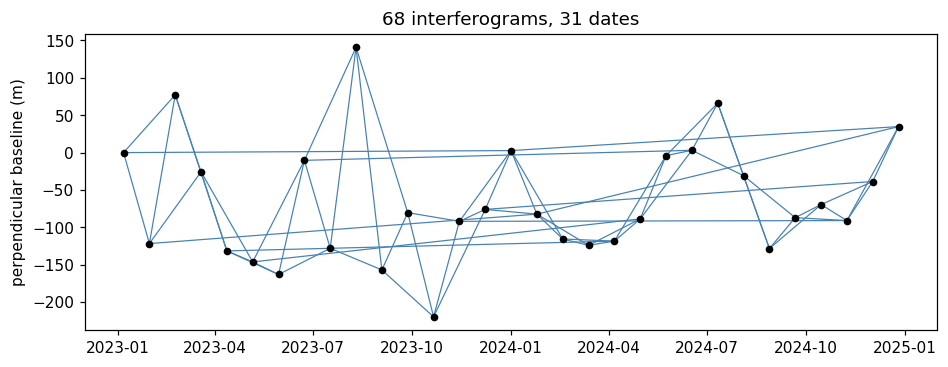

In [3]:
import datetime as dt
D = lambda s: dt.datetime.strptime(s, "%Y%m%d")
dates = sorted({d for p in pairs for d in p})
bp = {dates[0]: 0.0}
for (a, b), B in sorted(zip(pairs, z["bperp"]), key=lambda t: t[0][0]):   # approximate per-date baseline for the plot
    bp.setdefault(b, bp.get(a, 0) + float(B))
fig, ax = plt.subplots(figsize=(10, 3.5))
for a, b in pairs:
    ax.plot([D(a), D(b)], [bp.get(a, 0), bp.get(b, 0)], "-", color="steelblue", lw=0.8)
ax.plot([D(d) for d in dates], [bp.get(d, 0) for d in dates], "o", color="k", ms=4)
ax.set_ylabel("perpendicular baseline (m)"); ax.set_title(f"{len(pairs)} interferograms, {len(dates)} dates"); plt.show()

# A reference point

InSAR measures motion **relative** to somewhere. We pick a reference pixel that is coherent and, according to the
full-area MintPy result (referenced to the limestone Mulri hills west of the city), is not moving. Subtracting its
phase from every interferogram also removes atmosphere common to the whole crop.

In [4]:
mv = z["mintpy_vel_los_mmyr"]; cm = np.nanmean(coh, 0)
score = np.where((cm > 0.7) & np.isfinite(mv) & np.isfinite(unw).all(0), np.abs(mv), np.inf)   # coherent, unwrapped in every pair, still
r0, c0 = np.unravel_index(np.argmin(score), score.shape)
print(f"reference pixel row {r0}, col {c0}; coherence {cm[r0, c0]:.2f}; MintPy velocity there {mv[r0, c0]:+.2f} mm/yr")
unw_ref = unw - unw[:, r0:r0 + 1, c0:c0 + 1]

reference pixel row 62, col 24; coherence 0.90; MintPy velocity there +0.00 mm/yr


# The small-baseline inversion

Unknowns: the phase at each date relative to the first, $\phi_1 = 0, \phi_2, \dots, \phi_N$. Each interferogram
between dates $i$ and $j$ observes $\phi_j - \phi_i$. Stack these equations into a **design matrix** $A$ (one row per
interferogram, one column per date after the first, entries −1 and +1) and solve

$$ A\,\boldsymbol\phi = \Delta\boldsymbol\phi_{\text{ifg}} $$

by least squares, independently for every pixel. With more interferograms than dates the system is redundant, so
errors in single interferograms are averaged down. This is the core of the Small BAseline Subset (SBAS) method
(Berardino et al., 2002) that MintPy implements.

In [5]:
idx = {d: i for i, d in enumerate(dates)}
A = np.zeros((len(pairs), len(dates) - 1))
for r, (a, b) in enumerate(pairs):
    if idx[a] > 0: A[r, idx[a] - 1] = -1
    if idx[b] > 0: A[r, idx[b] - 1] = 1
print("design matrix", A.shape, " rank", np.linalg.matrix_rank(A), "(must equal the number of unknowns for one connected network)")

n, h, w = unw_ref.shape
Y = unw_ref.reshape(n, -1)
ok = np.all(np.isfinite(Y), axis=0)               # pixels unwrapped in every interferogram
phi = np.full((len(dates) - 1, h * w), np.nan, "float32")
phi[:, ok] = np.linalg.lstsq(A, Y[:, ok], rcond=None)[0]
phi = np.vstack([np.zeros((1, h * w)), phi]).reshape(len(dates), h, w)
disp_mm = -lam / (4 * np.pi) * phi * 1000          # line-of-sight change, mm (negative = away from the satellite)
print("pixels inverted:", ok.sum(), "of", ok.size)

design matrix (68, 30)  rank 30 (must equal the number of unknowns for one connected network)


pixels inverted: 30589 of 32725


# Velocity, and from line of sight to vertical

A straight line through each pixel's time series gives its velocity. Sentinel-1 looks sideways at about 30–45°, so it
measures motion along its line of sight (LOS). If the ground only moves **vertically**, as in compaction-driven
subsidence, then vertical = LOS / cos(incidence angle). Motion away from the satellite (negative here) is sinking.

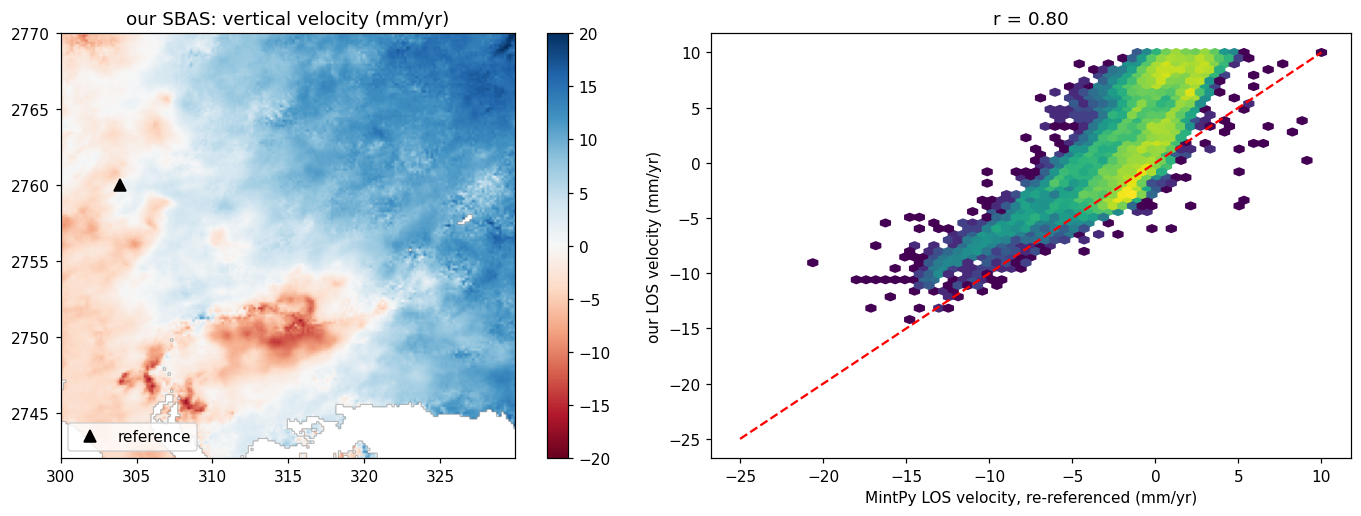

In [6]:
t = np.array([(D(d) - D(dates[0])).days / 365.25 for d in dates])
tt = t - t.mean()
vel_los = np.tensordot(tt, disp_mm - disp_mm.mean(0), axes=(0, 0)) / np.sum(tt ** 2)
vel_up = vel_los / np.cos(np.deg2rad(z["inc_deg"]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
im = ax[0].imshow(vel_up, cmap="RdBu", vmin=-20, vmax=20, extent=ext); ax[0].set_title("our SBAS: vertical velocity (mm/yr)")
plt.colorbar(im, ax=ax[0])
ax[0].plot(ext[0] + (c0 + .5) * z["cell"] / 1e3, ext[3] - (r0 + .5) * z["cell"] / 1e3, "k^", ms=8, label="reference"); ax[0].legend(loc="lower left")
m = np.isfinite(vel_los) & np.isfinite(mv)
ax[1].hexbin(mv[m] - mv[r0, c0], vel_los[m], gridsize=60, bins="log", extent=(-25, 10, -25, 10))
ax[1].plot([-25, 10], [-25, 10], "r--"); ax[1].set_xlabel("MintPy LOS velocity, re-referenced (mm/yr)"); ax[1].set_ylabel("our LOS velocity (mm/yr)")
ax[1].set_title(f"r = {np.corrcoef(mv[m] - mv[r0, c0], vel_los[m])[0, 1]:.2f}")
plt.tight_layout(); plt.show()

Our ten lines of numpy find the same bowl of subsidence as MintPy (r about 0.8), centred on Korangi and Landhi. But
the east of the crop appears to rise steadily, and our velocities sit above MintPy's on the right of the scatter
plot. That is a **ramp**: a tilt across the whole image, left by orbit errors and large-scale atmosphere, that
happens to grow over time. Real ground motion is rarely a perfect plane 30 km wide, so the usual remedy is to fit a
plane to each date's displacement and remove it. MintPy did this (`mintpy.deramp = linear`). The cost: a genuine
regional tilt would be removed too.

# Removing the ramp

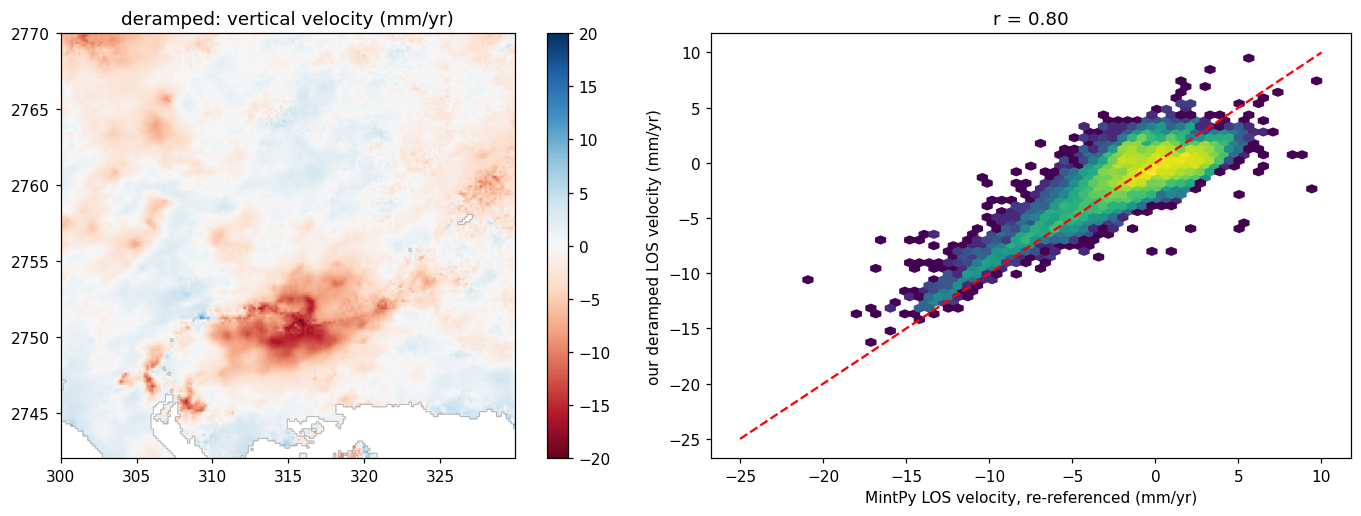

In [7]:
yy, xx = np.mgrid[0:h, 0:w]
G = np.c_[np.ones(h * w), xx.ravel(), yy.ravel()]
good = np.isfinite(disp_mm[-1]).ravel() & (cm.ravel() > 0.7)
disp_dr = disp_mm.copy()
for i in range(len(dates)):
    plane = G @ np.linalg.lstsq(G[good], disp_mm[i].ravel()[good], rcond=None)[0]
    disp_dr[i] = disp_mm[i] - plane.reshape(h, w)
disp_dr -= disp_dr[:, r0:r0 + 1, c0:c0 + 1]          # keep the reference at zero
vel_los2 = np.tensordot(tt, disp_dr - disp_dr.mean(0), axes=(0, 0)) / np.sum(tt ** 2)
vel_up2 = vel_los2 / np.cos(np.deg2rad(z["inc_deg"]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
im = ax[0].imshow(vel_up2, cmap="RdBu", vmin=-20, vmax=20, extent=ext); ax[0].set_title("deramped: vertical velocity (mm/yr)")
plt.colorbar(im, ax=ax[0])
m = np.isfinite(vel_los2) & np.isfinite(mv)
ax[1].hexbin(mv[m] - mv[r0, c0], vel_los2[m], gridsize=60, bins="log", extent=(-25, 10, -25, 10))
ax[1].plot([-25, 10], [-25, 10], "r--"); ax[1].set_xlabel("MintPy LOS velocity, re-referenced (mm/yr)"); ax[1].set_ylabel("our deramped LOS velocity (mm/yr)")
ax[1].set_title(f"r = {np.corrcoef(mv[m] - mv[r0, c0], vel_los2[m])[0, 1]:.2f}")
plt.tight_layout(); plt.show()

With the ramp gone, the scatter follows the 1:1 line: our values now agree with MintPy in level as well as pattern. The
remaining differences come from steps we skipped: MintPy
also estimates the DEM error from the baselines, masks pixels whose time series do not fit the network (temporal
coherence), and fits the ramp over its whole 55 × 45 km area rather than our crop.

# One pixel through time

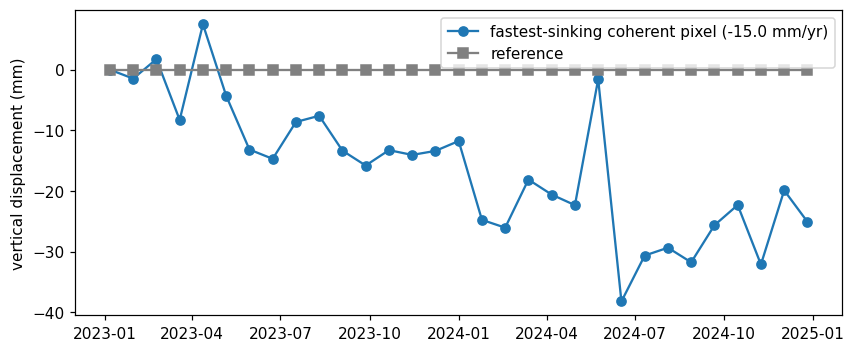

In [8]:
r1, c1 = np.unravel_index(np.nanargmin(np.where(cm > 0.7, mv, np.nan)), mv.shape)   # fastest sinking by MintPy
up = disp_dr / np.cos(np.deg2rad(z["inc_deg"]))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot([D(d) for d in dates], up[:, r1, c1], "o-", label=f"fastest-sinking coherent pixel ({vel_up2[r1, c1]:.1f} mm/yr)")
ax.plot([D(d) for d in dates], up[:, r0, c0], "s-", color="grey", label="reference")
ax.set_ylabel("vertical displacement (mm)"); ax.legend(); plt.show()

The sinking pixel trends down over the two years, but single dates scatter by a centimetre or more: that scatter is
mostly water vapour in the atmosphere on each date, which the network cannot remove because it is different every
time. A velocity fitted over two years averages much of it out; more dates, and a tropospheric correction from a
weather model such as ERA5, would tighten it further.

# Run the whole thing yourself

The full-area result came from two programs, run from the commons-city repository:

```python
# 1. order interferograms from ASF HyP3 (needs a free NASA Earthdata login in ~/.netrc)
import hyp3_sdk as sdk
hyp3 = sdk.HyP3()
hyp3.submit_insar_job(reference_granule, secondary_granule, name="karachi", looks="20x4",
                      include_look_vectors=True, include_dem=True, apply_water_mask=True)
jobs = hyp3.watch(hyp3.find_jobs(name="karachi")); jobs.download_files("hyp3")
```

```text
# 2. MintPy (conda install -c conda-forge mintpy), configuration file karachi.cfg:
mintpy.load.processor   = hyp3
mintpy.load.unwFile     = clipped/*_unw_phase.tif     # all products cropped to one common grid first
mintpy.load.corFile     = clipped/*_corr.tif
mintpy.reference.lalo   = 24.97,66.98                 # stable limestone hills
mintpy.network.coherenceBased = yes
mintpy.deramp           = linear
smallbaselineApp.py karachi.cfg
```

# What to take away

1. Phase measures **change in distance**, in fractions of 2.8 cm; coherence tells you where to trust it.
2. A single interferogram is mostly atmosphere; a **network** inverted by least squares recovers motion that grows
   with time.
3. Every InSAR result is **relative** to a reference and **along the line of sight**; say which, and state the
   assumption (here: purely vertical motion) used to convert it.
4. Check the result against something independent before using it: GNSS stations, levelling, or a second orbit
   direction (a descending track separates vertical from east-west motion).